# 03c (previo) — Del estado oculto a la salida: cabezas y objetivos de

entrenamiento

> Esta página es el **previo conceptual de [03c — Fine-tuning
> eficiente](03c-fine-tuning.qmd)**: explica qué es una cabeza de salida
> y qué significan SFT, PPO y DPO antes de ajustar un modelo. Se
> recomienda haber leído antes [01a — Arquitectura
> Transformer](../bloque1/01a-transformer.qmd) y [01b — LLM e
> inferencia](../bloque1/01b-llms.qmd). Es lectura recomendada, no
> obligatoria.

> **Qué aprenderás**
>
> En [01a - Cómo funciona un Transformer de un
> vistazo](../bloque1/01a-transformer.qmd#sec-vistazo-transformer) vimos
> cómo una secuencia de tokens se transforma en estados ocultos
> contextualizados. En esta página seguimos el recorrido hasta la salida
> del modelo.
>
> La idea central es sencilla, pero conviene separar dos niveles que
> suelen mezclarse:
>
> - El *backbone* es el conjunto de capas Transformer que construye una
>   representación contextual para cada posición.
> - Una cabeza de salida transforma esas representaciones en el
>   resultado que necesita una tarea.
> - SFT, PPO y DPO no son cabezas distintas, sino procedimientos y
>   objetivos de entrenamiento.
>
> Esta distinción permite entender por qué un mismo modelo puede
> producir tokens, estimar el valor de un estado o puntuar una
> respuesta.

## 1. Del texto a los estados ocultos

Para concretar la explicación, pensemos en un Transformer causal de tipo
*decoder-only*. Después de procesar una secuencia de longitud $T$, el
*backbone* produce una matriz de estados ocultos:

$$
H = (\mathbf{h}_1, \mathbf{h}_2, \ldots, \mathbf{h}_T)
\in \mathbb{R}^{B \times T \times d}
$$

Aquí, $B$ es el tamaño del lote, $T$ la longitud de la secuencia y $d$
la dimensión del modelo. Cada vector $\mathbf{h}_t$ resume la
información que el modelo ha construido en la posición $t$. En un modelo
causal, esa información solo puede depender de los tokens anteriores y
del token actual.

El *backbone* no produce directamente una respuesta en lenguaje natural.
Produce representaciones numéricas que otra capa debe interpretar. Esa
capa es la cabeza de salida.

<figure id="fig-backbone-cabezas">
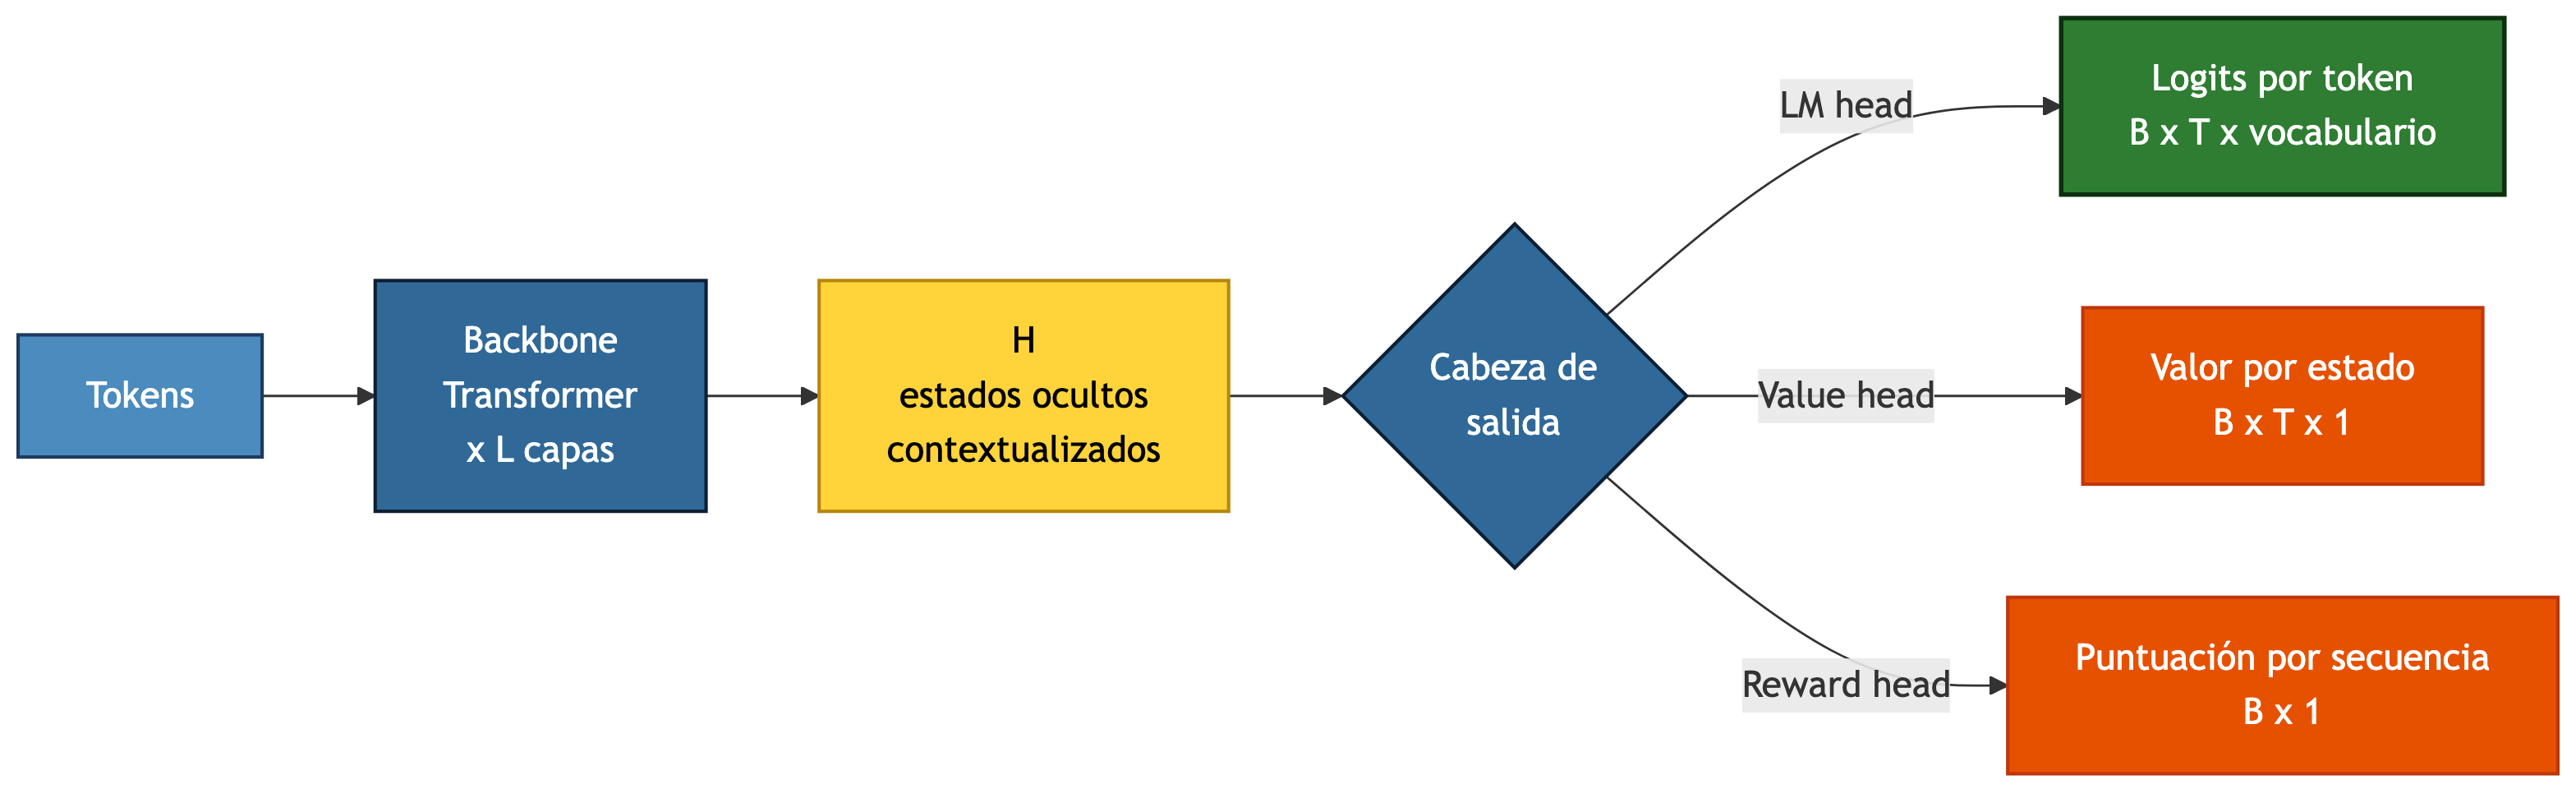
<figcaption>Figura 1: El backbone produce estados ocultos que distintas
cabezas transforman en salidas diferentes.</figcaption>
</figure>

Como muestra
<a href="#fig-backbone-cabezas" class="quarto-xref">Figura 1</a>, las
cabezas no reciben necesariamente la misma parte de $H$. La *LM head*
utiliza todos los estados para producir una distribución por token; la
*value head* suele producir un valor por posición; la *reward head*
resume la secuencia completa en un único escalar.

La separación es conceptual. En una implementación concreta, el
*backbone* puede congelarse, ajustarse mediante adaptadores o copiarse
para formar modelos especializados. Lo importante es distinguir la
representación compartida de la capa que la convierte en una salida.

> **Una regla útil**
>
> Si la salida es una distribución sobre tokens, probablemente estamos
> ante una *LM head*. Si la salida es un escalar que resume un estado o
> una secuencia, probablemente estamos ante una cabeza de valor o de
> recompensa.

## 2. LM head: predecir el siguiente token

La *LM head* es una proyección lineal desde la dimensión del modelo
hasta el tamaño del vocabulario. Para cada posición, transforma el
estado oculto en un vector de logits:

$$
\mathbf{z}_t = W_{\text{LM}}\mathbf{h}_t + \mathbf{b}
\in \mathbb{R}^{|\mathcal{V}|}
$$

La función *softmax* convierte esos logits en probabilidades:

$$
P(x_{t+1} \mid x_{\leq t})
= \operatorname{softmax}(\mathbf{z}_t)
$$

El modelo no genera una frase completa de una sola vez. En cada paso
calcula una distribución, selecciona o muestrea un token y lo incorpora
al contexto. Después vuelve a calcular la salida para predecir el
siguiente token.

Durante el preentrenamiento, la pérdida causal compara la distribución
producida en cada posición con el token que debería aparecer a
continuación:

$$
\mathcal{L}_{\text{LM}}
= -\frac{1}{T}\sum_{t=1}^{T}
\log P(x_{t+1}\mid x_{\leq t})
$$

Por eso la salida de la *LM head* tiene una dimensión grande: si el
vocabulario contiene $|\mathcal{V}|$ tokens, cada posición produce ese
número de logits.

<figure id="fig-alineacion-sft">

<figcaption>Figura 2: Una misma secuencia puede dar lugar a logits por
posición, una máscara de pérdida SFT, valores por estado o una
recompensa por secuencia.</figcaption>
</figure>

La figura <a href="#fig-alineacion-sft" class="quarto-xref">Figura 2</a>
reúne las salidas en una misma secuencia. La fila de logits conserva una
salida para cada posición; la máscara SFT selecciona cuáles de esas
posiciones contribuyen a la pérdida; la *value head* mantiene una
estimación por estado; y la *reward head* resume la trayectoria completa
en un único escalar.

### Weight tying

Muchos LLM comparten los pesos de la tabla de embeddings con la
proyección de salida. En ese caso:

$$
W_{\text{LM}} = E^{\mathsf{T}}
$$

Esta decisión reduce el número de parámetros y conecta geométricamente
la representación de entrada con la representación de salida. No es una
propiedad obligatoria, pero sí una práctica habitual en modelos de
lenguaje causales.

## 3. SFT: la misma LM head, una pérdida distinta

El ajuste fino supervisado, o SFT (*Supervised Fine-Tuning*), enseña al
modelo a responder a instrucciones mediante ejemplos de conversación o
de formato instrucción-respuesta. No requiere una cabeza arquitectónica
nueva: se sigue utilizando la *LM head*.

Lo que cambia es el conjunto de datos y la máscara de la pérdida. El
prompt proporciona el contexto, pero normalmente se calcula la pérdida
solo sobre los tokens que debe producir el asistente:

$$
\mathcal{L}_{\text{SFT}}
= -\frac{1}{\sum_{t=1}^{T}m_t}
\sum_{t=1}^{T}m_t\log P(y_t\mid x, y_{<t})
$$

La máscara $m_t$ vale cero para los tokens que no queremos utilizar como
objetivo y uno para los tokens de la respuesta. En muchas
implementaciones, los objetivos ignorados se representan con el valor
`-100`.

| Token         | `<user>` | `explica` | `<assistant>` | `La` | `atención` |
|---------------|---------:|----------:|--------------:|-----:|-----------:|
| Máscara $m_t$ |        0 |         0 |             0 |    1 |          1 |
| Etiqueta      |   `-100` |    `-100` |        `-100` | `La` | `atención` |

El formato conversacional también importa. Los tokens especiales, las
plantillas de chat y la forma de separar las intervenciones indican al
modelo qué parte corresponde al usuario y cuál al asistente. La máscara
no convierte por sí sola un modelo en un asistente; funciona junto con
datos de instrucciones y un procedimiento de entrenamiento supervisado.

> **SFT no es una cuarta cabeza**
>
> La expresión “SFT head” resulta cómoda como abreviatura, pero es
> arquitectónicamente imprecisa. SFT describe una fase de entrenamiento
> de la *LM head*, no una capa de salida independiente.

## 4. Value head: estimar el valor de un estado

En aprendizaje por refuerzo, el modelo necesita algo más que una
distribución sobre tokens. También puede necesitar una estimación de lo
prometedor que es el estado actual. La función de valor de una política
$\pi$ se define como el retorno esperado a partir de ese estado:

$$
V^{\pi}(s_t)
= \mathbb{E}_{\pi}\left[
\sum_{k=0}^{\infty}\gamma^k r_{t+k}
\mid s_t
\right]
$$

Una *value head* suele ser una capa lineal $d \to 1$ aplicada a cada
estado oculto:

$$
V(s_t) = \mathbf{w}_{\text{value}}^{\mathsf{T}}\mathbf{h}_t + b
\in \mathbb{R}
$$

La *value head* no sustituye necesariamente a la *LM head*. En un modelo
actor-crítico, ambas ramas pueden coexistir:

``` text
Backbone
|-- LM head       -> distribución de acciones, normalmente tokens
`-- Value head    -> V(s_t), valor estimado del estado
```

La política utiliza los logits para elegir tokens. El crítico utiliza
los valores para calcular ventajas y estabilizar la actualización de la
política. En PPO, por ejemplo, la pérdida de valor puede expresarse como
un error cuadrático entre el valor predicho y un retorno estimado:

$$
\mathcal{L}_{V}
= \frac{1}{T}\sum_{t=1}^{T}
\left(V(s_t)-R_t\right)^2
$$

La forma exacta de la cabeza y su inicialización dependen de la
biblioteca y del algoritmo. Lo esencial es que produce un escalar por
estado y que su función es distinta de la predicción del siguiente
token.

<figure id="fig-value-reward">

<figcaption>Figura 3: Diferencia entre el valor estimado en cada estado
y la recompensa asignada a una respuesta completa.</figcaption>
</figure>

Como muestra
<a href="#fig-value-reward" class="quarto-xref">Figura 3</a>, la *value
head* responde a una pregunta local: qué retorno se espera desde cada
estado. La *reward head* responde a una pregunta global: qué puntuación
recibe la respuesta completa. El modelo de recompensa puede comparar
después dos respuestas mediante la diferencia entre sus puntuaciones.

## 5. Reward head: puntuar una respuesta

Un modelo de recompensa asigna una puntuación a una respuesta completa.
Se entrena a partir de preferencias: dada una entrada $x$, una persona o
un proceso de evaluación indica cuál de dos respuestas es preferible,
$y^+$ o $y^-$.

El modelo de recompensa puede compartir una arquitectura de lenguaje con
el modelo base y sustituir la proyección al vocabulario por una capa
escalar. En modelos *decoder-only* es habitual utilizar el estado del
último token válido, el token de fin de secuencia o alguna forma de
*pooling*:

$$
r_{\theta}(x,y)
= \mathbf{w}_{\text{reward}}^{\mathsf{T}}\mathbf{h}_{\text{pool}} + b
\in \mathbb{R}
$$

En el modelo de Bradley-Terry, la probabilidad de preferir la respuesta
elegida se modela como:

$$
P(y^+ \succ y^- \mid x)
= \sigma\left(
r_{\theta}(x,y^+) - r_{\theta}(x,y^-)
\right)
$$

La pérdida correspondiente es:

$$
\mathcal{L}_{\text{RM}}
= -\log \sigma\left(
r_{\theta}(x,y^+) - r_{\theta}(x,y^-)
\right)
$$

La puntuación no debe interpretarse automáticamente como una medida
absoluta de calidad. El objetivo principal es ordenar respuestas de
acuerdo con los patrones de preferencia presentes en los datos.

## 6. PPO y DPO: dos rutas de optimización

La *reward head* y la *value head* aparecen sobre todo cuando se utiliza
una ruta de aprendizaje por refuerzo como PPO. La relación entre
componentes y fases se entiende mejor separando las dos rutas:

<figure id="fig-rutas-preferencias">
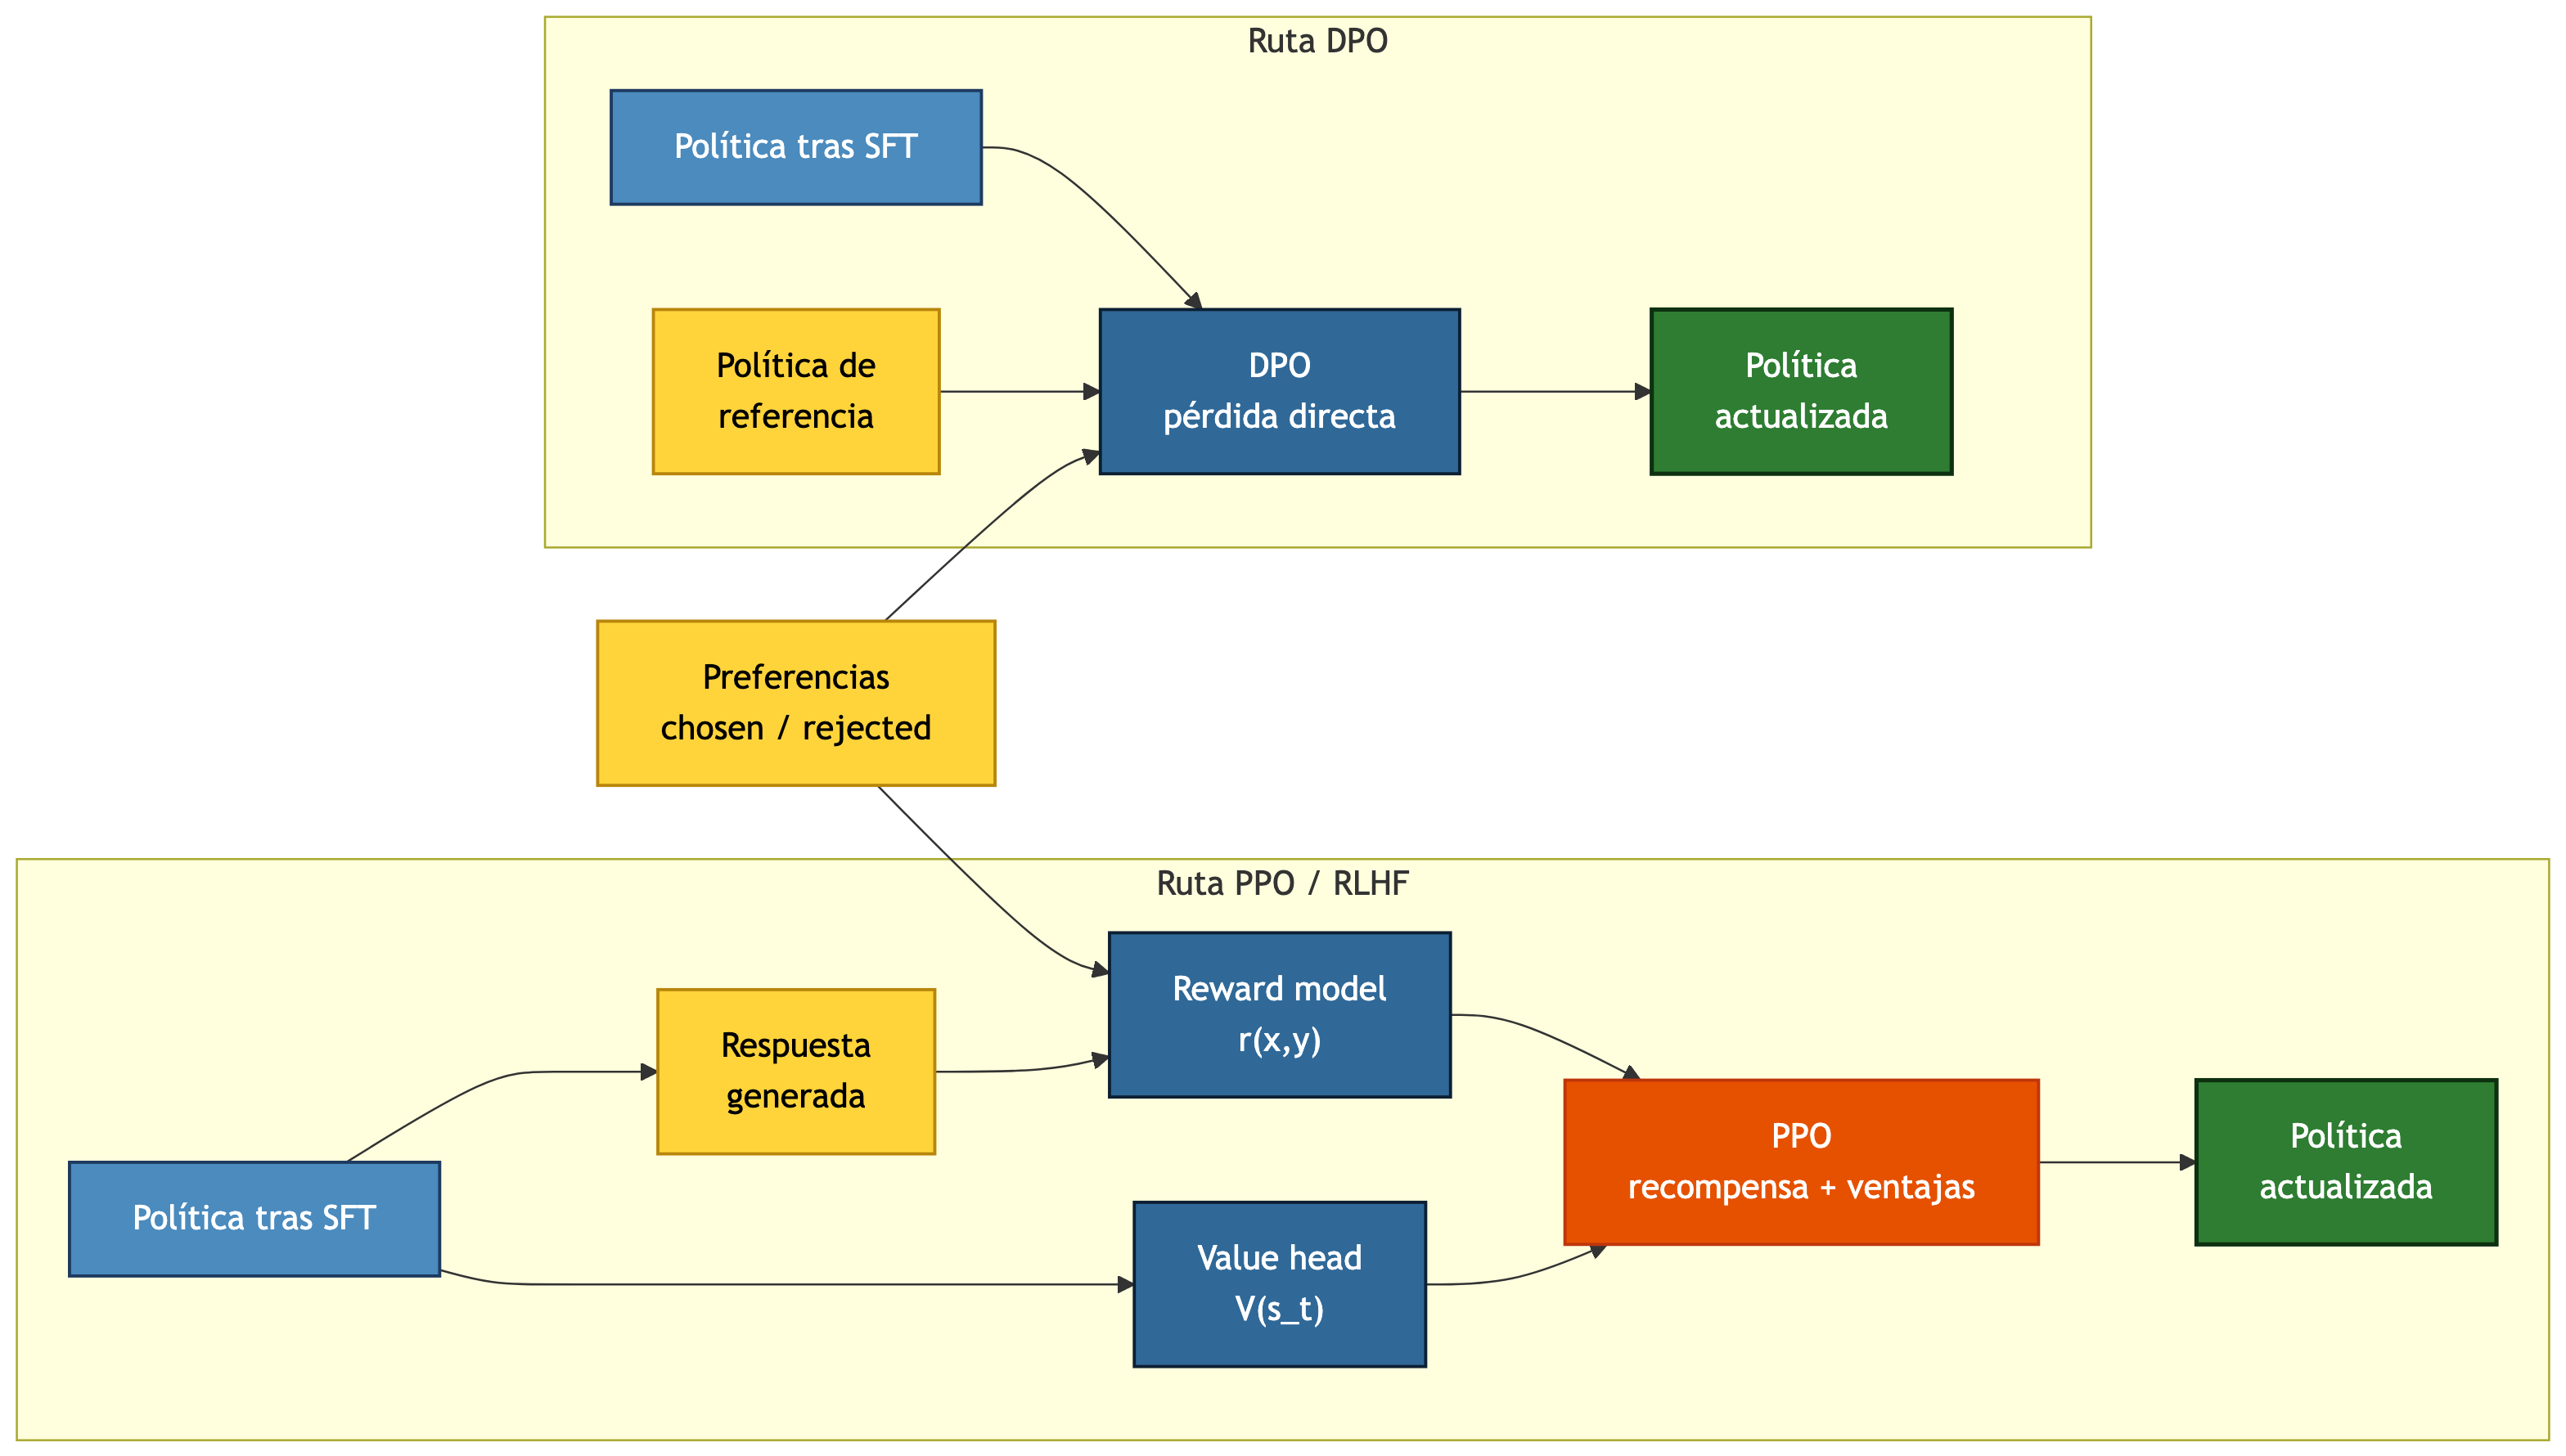
<figcaption>Figura 4: PPO y DPO utilizan las preferencias mediante rutas
de optimización diferentes.</figcaption>
</figure>

En RLHF con PPO, el *reward model* transforma la respuesta en una señal
de recompensa y la *value head* ayuda a estimar las ventajas durante la
actualización de la política. Esta familia de métodos se popularizó en
trabajos de alineamiento con preferencias humanas
(<span class="nocase">Ouyang et al.</span>, 2022; Schulman et al.,
2017).

DPO (*Direct Preference Optimization*) utiliza directamente los pares de
preferencias y una política de referencia congelada. No necesita
entrenar un *reward model* separado como paso intermedio (Rafailov
et al., 2023). Por tanto, no conviene presentar la *reward head* como
una pieza necesaria de todo sistema de alineamiento.

## 7. Dónde encaja LoRA

El ajuste eficiente de parámetros introduce otra distinción. LoRA
(*Low-Rank Adaptation*) no significa necesariamente entrenar solo la
cabeza de salida. Lo habitual es añadir matrices de bajo rango en
módulos seleccionados del *backbone*, por ejemplo en las proyecciones de
consulta y valor de la atención (Hu et al., 2022).

El modelo base puede permanecer congelado mientras se entrenan esos
adaptadores. El resultado sigue utilizando la misma LM head, pero el
*backbone* produce estados ocultos diferentes porque los adaptadores han
modificado su transformación. En prompt tuning, en cambio, se aprenden
vectores adicionales que se incorporan a la entrada (Lester et al.,
2021).

La explicación detallada de LoRA aparece en [03c - Fine-tuning
eficiente](03c-fine-tuning.qmd#sec-lora). Aquí basta con conservar la
separación:

| Concepto | Qué describe                                                |
|----------|-------------------------------------------------------------|
| Cabeza   | Componente que transforma estados ocultos en una salida     |
| SFT      | Objetivo supervisado para entrenar una política             |
| LoRA     | Forma de adaptar determinados pesos con pocos parámetros    |
| PPO      | Algoritmo de optimización mediante aprendizaje por refuerzo |
| DPO      | Optimización directa a partir de preferencias               |

## 8. Resumen: tres cabezas y varias fases

La comparación arquitectónica se resume en
<a href="#tbl-cabezas-resumen" class="quarto-xref">Tabla 1</a>. SFT
aparece como fase de entrenamiento, no como una cabeza adicional.

| Componente o fase | Salida principal | Señal de entrenamiento | Función |
|------------------|------------------|------------------|------------------|
| LM head | Un vector de logits por posición | Cross-entropy causal | Predecir el siguiente token |
| SFT | La misma salida de la LM head | Cross-entropy enmascarada | Aprender a seguir instrucciones |
| Value head | Un escalar por estado | Error sobre retornos estimados | Estimar el valor para el crítico |
| Reward head | Un escalar por secuencia | Preferencias entre respuestas | Ordenar respuestas según una señal de recompensa |
| PPO | Política más value head y reward model | Objetivo de aprendizaje por refuerzo | Optimizar la política mediante recompensas |
| DPO | Política y referencia | Pares de preferencias | Optimizar directamente la preferencia relativa |

Tabla 1: Componentes de salida y objetivos de entrenamiento

> **La idea que conviene conservar**
>
> El *backbone* construye representaciones contextuales. La cabeza
> determina cómo se leen esas representaciones. SFT, PPO, DPO y LoRA
> describen formas de entrenar o adaptar el sistema; no son nombres
> alternativos para cabezas de salida.

Esta distinción conecta la página con el resto del módulo:

- En el Bloque 2, las llamadas a un LLM utilizan la política y su *LM
  head* para producir tokens.
- En la página siguiente de este bloque ([03c](03c-fine-tuning.qmd)),
  SFT y LoRA permiten adaptar el comportamiento a instrucciones o datos
  de dominio.
- En el Bloque 4, los modelos de recompensa y los evaluadores
  *LLM-as-a-judge* pueden proporcionar señales de evaluación, pero no
  son equivalentes por definición.

La pregunta práctica que debe guiar la lectura de un paper es: ¿qué
representación produce el modelo, qué salida se calcula a partir de ella
y con qué señal se entrenan sus parámetros?

------------------------------------------------------------------------

> Continúa con **[03c — Fine-tuning eficiente](03c-fine-tuning.qmd)**,
> donde aplicarás SFT y LoRA.

# References

Hu, E. J., Shen, Y., Wallis, P., Allen-Zhu, Z., Li, Y., Wang, S., Wang,
L., & Chen, W. (2022). LoRA: Low-Rank Adaptation of Large Language
Models. *International Conference on Learning Representations (ICLR)*.
<https://arxiv.org/abs/2106.09685>

Lester, B., Al-Rfou, R., & Constant, N. (2021). The Power of Scale for
Parameter-Efficient Prompt Tuning. *Proceedings of the 2021 Conference
on Empirical Methods in Natural Language Processing (EMNLP)*, 3045-3059.
<https://doi.org/10.18653/v1/2021.emnlp-main.243>

<span class="nocase">Ouyang, L., Wu, J., Jiang, X., Almeida, D.,
Wainwright, C., Mishkin, P., Zhang, C., Agarwal, S., Slama, K., Ray, A.,
et al.</span> (2022). Training Language Models to Follow Instructions
with Human Feedback. *Advances in Neural Information Processing
Systems*, *35*. <https://arxiv.org/abs/2203.02155>

Rafailov, R., Sharma, A., Mitchell, E., Manning, C. D., Ermon, S., &
Finn, C. (2023). Direct Preference Optimization: Your Language Model is
Secretly a Reward Model. *Advances in Neural Information Processing
Systems*, *36*. <https://arxiv.org/abs/2305.18290>

Schulman, J., Wolski, F., Dhariwal, P., Radford, A., & Klimov, O.
(2017). Proximal Policy Optimization Algorithms. *arXiv preprint
arXiv:1707.06347*. <https://arxiv.org/abs/1707.06347>